# Tahap 1: Exploratory Data Analysis (EDA) & Statistika Deskriptif
**Projek**: PSAJ Matematika Terintegrasi PPLG SMK Telkom Purwokerto  
**Sistem**: LaborCast — Peramalan Tingkat Pengangguran Terbuka (TPT)  
**Dataset**: BPS Sakernas Nasional 2015–2025 & Potong Lintang 38 Provinsi 2025

Tahap ini berfokus pada eksplorasi awal struktur data, pengecekan anomali dan missing values, perhitungan ukuran pemusatan dan penyebaran lengkap, pembuatan tabel distribusi frekuensi aturan Sturges, analisis deteksi pencilan (syok COVID-19), serta telaah mendalam terhadap pergerakan laju perubahan tahunan ($\Delta Y_t$).

In [1]:
import sys
import os

# Menemukan direktori proyek secara dinamis dan menambahkan src ke sys.path
curr = os.path.abspath('.')
for p in [curr, os.path.abspath('..'), os.path.abspath('../..')]:
    src_path = os.path.join(p, 'src')
    if os.path.exists(src_path):
        if src_path not in sys.path:
            sys.path.insert(0, src_path)
        if p not in sys.path:
            sys.path.insert(0, p)
        break

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.size'] = 10
plt.rcParams['figure.dpi'] = 150
print("Inisialisasi lingkungan dan pustaka berhasil.")
from laborcast.data import DataLoader, DatasetValidator, DataPreprocessor


Inisialisasi lingkungan dan pustaka berhasil.


## 1. Pemuatan dan Validasi Dataset Resmi Sakernas BPS

In [2]:
loader = DataLoader()
df_ts = loader.load_national_timeseries()
DatasetValidator.validate(df_ts, require_february=True)

print("Dataset Runtun Waktu Nasional Sakernas BPS (2015-2025):")
display(df_ts)

Dataset Runtun Waktu Nasional Sakernas BPS (2015-2025):


,Tahun,TPT_Februari,TPT_Agustus
0,2015,5.81,6.18
1,2016,5.50,5.61
2,2017,5.33,5.50
3,2018,5.10,5.34
4,2019,4.98,5.23
5,2020,4.94,7.07
6,2021,6.26,6.49
7,2022,5.83,5.86
8,2023,5.45,5.32
9,2024,4.82,4.91


## 2. Statistika Deskriptif Lengkap Data Tunggal

In [3]:
y_all = df_ts['TPT_Agustus'].values
y_post = df_ts[df_ts['Tahun'] >= 2020]['TPT_Agustus'].values

def compute_stats(arr, label):
    n = len(arr)
    mean_val = np.mean(arr)
    med_val = np.median(arr)
    q1 = np.percentile(arr, 25)
    q3 = np.percentile(arr, 75)
    iqr = q3 - q1
    qd = iqr / 2.0
    var_s = np.var(arr, ddof=1)
    std_s = np.std(arr, ddof=1)
    cv = (std_s / mean_val) * 100.0
    return {
        "Dataset": label, "Jumlah Data (n)": n, "Mean (%)": round(mean_val, 4),
        "Median (%)": round(med_val, 4), "Min (%)": round(np.min(arr), 4),
        "Max (%)": round(np.max(arr), 4), "Jangkauan (R)": round(np.ptp(arr), 4),
        "Q1 (%)": round(q1, 4), "Q3 (%)": round(q3, 4), "IQR (%)": round(iqr, 4),
        "Simpangan Kuartil (Qd)": round(qd, 4), "Varians (s^2)": round(var_s, 4),
        "Standar Deviasi (s)": round(std_s, 4), "Koefisien Variasi (%)": round(cv, 2)
    }

summary_df = pd.DataFrame([
    compute_stats(y_all, "Historis Penuh (2015-2025)"),
    compute_stats(y_post, "Pascapandemi (2020-2025)")
])
display(summary_df.T)

,0,1
Dataset,Historis Penuh (2015-2025),Pascapandemi (2020-2025)
Jumlah Data (n),11,6
Mean (%),5.6691,5.75
Median (%),5.5,5.59
Min (%),4.85,4.85
Max (%),7.07,7.07
Jangkauan (R),2.22,2.22
Q1 (%),5.275,5.0125
Q3 (%),6.02,6.3325
IQR (%),0.745,1.32


## 3. Tabel Distribusi Frekuensi Berkelompok (Aturan Sturges, n=38 Provinsi 2025)

In [4]:
df_y_prov = loader.load_provincial_tpt()
y_prov = df_y_prov['TPT_Agustus'].values

n_prov = len(y_prov)
k_sturges = int(round(1 + 3.322 * np.log10(n_prov))) # k = 6 kelas
edges = [1.485, 2.405, 3.325, 4.245, 5.165, 6.085, 7.005]

rows = []
cum_less = 0
for i in range(len(edges)-1):
    tb = edges[i]
    ta = edges[i+1]
    mid = (tb + ta) / 2.0
    cnt = np.sum((y_prov >= tb) & (y_prov < ta)) if i < len(edges)-2 else np.sum((y_prov >= tb) & (y_prov <= ta))
    cum_less += cnt
    rel = (cnt / n_prov) * 100.0
    rows.append({
        "Kelas": f"{tb + 0.005:.2f} - {ta - 0.005:.2f}",
        "Tepi Bawah (Tb)": tb, "Tepi Atas (Ta)": ta, "Titik Tengah (xi)": round(mid, 3),
        "Frekuensi (fi)": cnt, "Relatif (%)": round(rel, 2), "Kumulatif (<=)": cum_less,
        "fi * xi": round(cnt * mid, 3)
    })

tabel_sturges_df = pd.DataFrame(rows)
display(tabel_sturges_df)

mean_grp = tabel_sturges_df['fi * xi'].sum() / n_prov
print(f"Mean Data Berkelompok: {mean_grp:.4f}%")

,Kelas,Tepi Bawah (Tb),Tepi Atas (Ta),Titik Tengah (xi),Frekuensi (fi),Relatif (%),Kumulatif (<=),fi * xi
0,1.49 - 2.40,1.485,2.405,1.945,2,5.26,2,3.890
1,2.41 - 3.32,2.405,3.325,2.865,5,13.16,7,14.325
2,3.33 - 4.24,3.325,4.245,3.785,13,34.21,20,49.205
3,4.25 - 5.16,4.245,5.165,4.705,6,15.79,26,28.230
4,5.17 - 6.08,5.165,6.085,5.625,6,15.79,32,33.750
5,6.09 - 7.00,6.085,7.005,6.545,6,15.79,38,39.270


Mean Data Berkelompok: 4.4387%


## 4. Analisis Dinamika Delta Laju Perubahan Tahunan (Deselerasi Penurunan)

In [5]:
years_post = df_ts[df_ts['Tahun'] >= 2020]['Tahun'].values
deltas = np.diff(y_post)
delta_labels = [f"{years_post[i]} -> {years_post[i+1]}" for i in range(len(deltas))]

delta_df = pd.DataFrame({
    "Transisi Tahun": delta_labels,
    "TPT Awal (%)": y_post[:-1],
    "TPT Akhir (%)": y_post[1:],
    "Laju Perubahan Delta (%)": deltas,
    "Status Dinamika": ["Pemulihan Awal", "Akselerasi Puncak", "Penyerapan Stabil", "Mulai Melambat", "Deselerasi Signifikan"]
})
display(delta_df)
print(f"Rata-rata Laju Perubahan Tahunan: {np.mean(deltas):.4f}%/tahun")
print(f"Standar Deviasi Laju Perubahan : {np.std(deltas, ddof=1):.4f}%")

,Transisi Tahun,TPT Awal (%),TPT Akhir (%),Laju Perubahan Delta (%),Status Dinamika
0,2020 -> 2021,7.07,6.49,-0.58,Pemulihan Awal
1,2021 -> 2022,6.49,5.86,-0.63,Akselerasi Puncak
2,2022 -> 2023,5.86,5.32,-0.54,Penyerapan Stabil
3,2023 -> 2024,5.32,4.91,-0.41,Mulai Melambat
4,2024 -> 2025,4.91,4.85,-0.06,Deselerasi Signifikan


Rata-rata Laju Perubahan Tahunan: -0.4440%/tahun
Standar Deviasi Laju Perubahan : 0.2296%


## 5. Visualisasi EDA Komprehensif

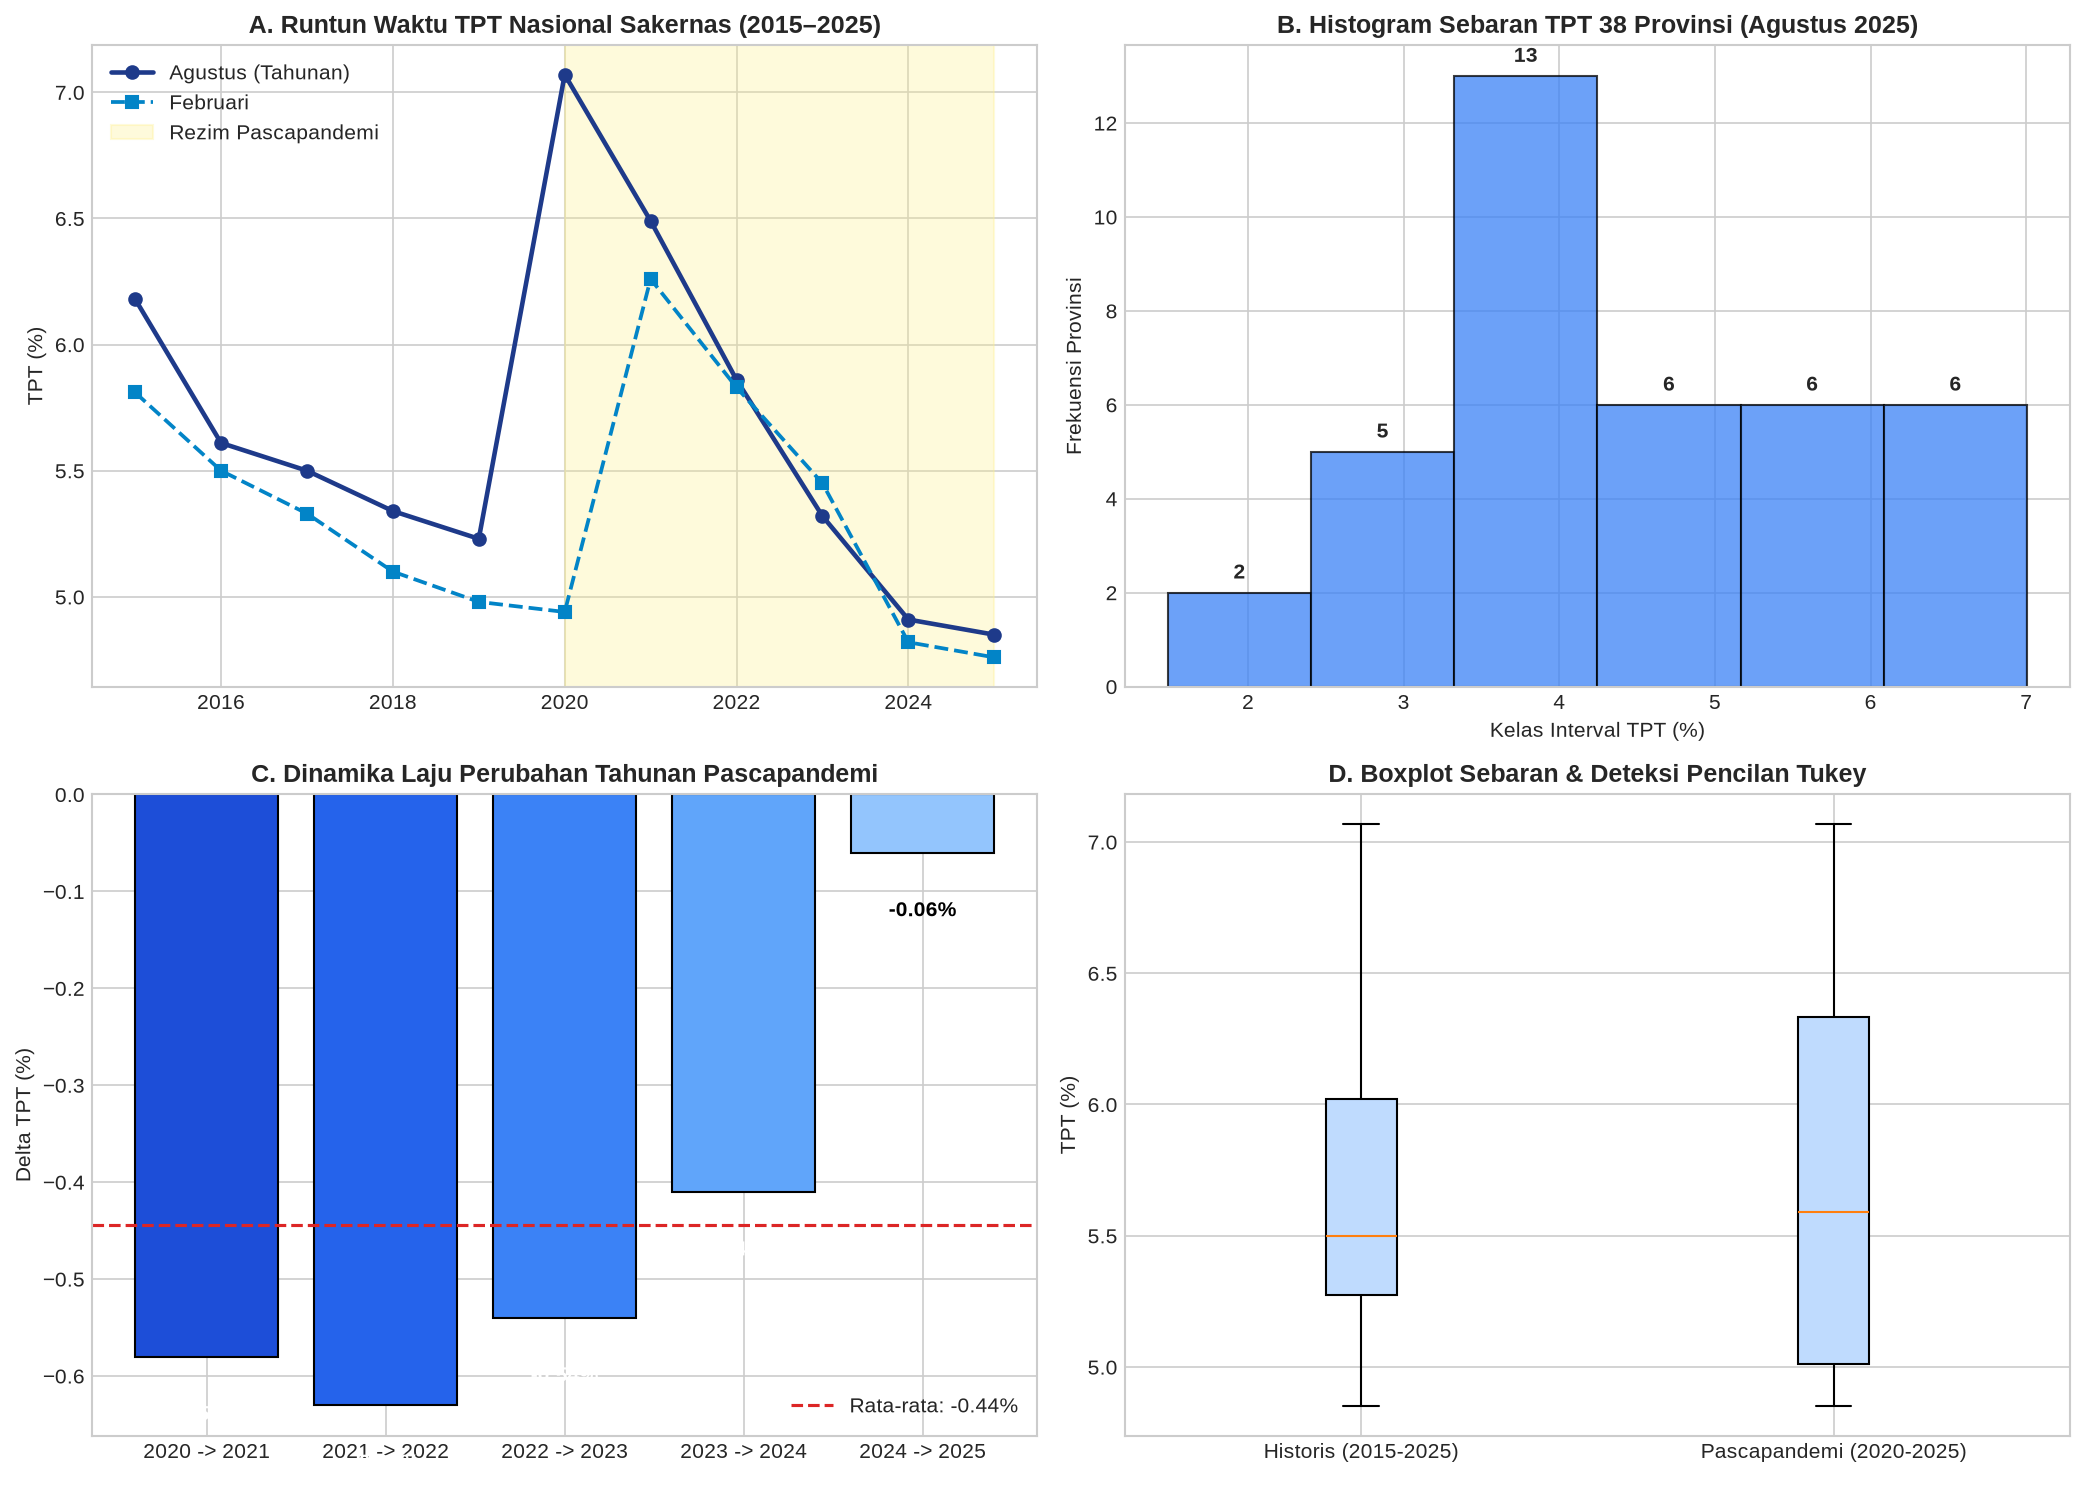

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Run Chart Tren Historis
axes[0, 0].plot(df_ts['Tahun'], df_ts['TPT_Agustus'], 'o-', color='#1e3a8a', linewidth=2.2, label='Agustus (Tahunan)')
axes[0, 0].plot(df_ts['Tahun'], df_ts['TPT_Februari'], 's--', color='#0284c7', linewidth=1.8, label='Februari')
axes[0, 0].axvspan(2020, 2025, color='#fef08a', alpha=0.3, label='Rezim Pascapandemi')
axes[0, 0].set_title("A. Runtun Waktu TPT Nasional Sakernas (2015–2025)", fontweight='bold')
axes[0, 0].set_ylabel("TPT (%)")
axes[0, 0].legend()

# 2. Histogram Distribusi 38 Provinsi 2025
counts, _, patches = axes[0, 1].hist(y_prov, bins=edges, edgecolor='black', color='#3b82f6', alpha=0.75)
for p, c in zip(patches, counts):
    if c > 0:
        axes[0, 1].text(p.get_x() + p.get_width()/2, p.get_height() + 0.3, f"{int(c)}", ha='center', fontweight='bold')
axes[0, 1].set_title("B. Histogram Sebaran TPT 38 Provinsi (Agustus 2025)", fontweight='bold')
axes[0, 1].set_xlabel("Kelas Interval TPT (%)")
axes[0, 1].set_ylabel("Frekuensi Provinsi")

# 3. Bar Chart Laju Delta Perubahan
bars = axes[1, 0].bar(delta_labels, deltas, color=['#1d4ed8', '#2563eb', '#3b82f6', '#60a5fa', '#93c5fd'], edgecolor='black')
for b in bars:
    val = b.get_height()
    axes[1, 0].text(b.get_x() + b.get_width()/2, val - 0.05, f"{val:.2f}%", ha='center', va='top', color='white' if abs(val)>0.3 else 'black', fontweight='bold')
axes[1, 0].axhline(0, color='black', linewidth=0.8)
axes[1, 0].axhline(np.mean(deltas), color='#dc2626', linestyle='--', label=f"Rata-rata: {np.mean(deltas):.2f}%")
axes[1, 0].set_title("C. Dinamika Laju Perubahan Tahunan Pascapandemi", fontweight='bold')
axes[1, 0].set_ylabel("Delta TPT (%)")
axes[1, 0].legend()

# 4. Boxplot Deteksi Pencilan
axes[1, 1].boxplot([y_all, y_post], tick_labels=['Historis (2015-2025)', 'Pascapandemi (2020-2025)'], patch_artist=True, boxprops=dict(facecolor='#bfdbfe'))
axes[1, 1].set_title("D. Boxplot Sebaran & Deteksi Pencilan Tukey", fontweight='bold')
axes[1, 1].set_ylabel("TPT (%)")

plt.tight_layout()
plt.show()

## Kesimpulan Tahap 1
1. Terdapat korelasi waktu yang sangat kuat dalam tren penurunan pascapandemi (2020–2025).
2. Terlihat bukti deselerasi penurunan mendekati batas jenuh alami ($4{,}85\%$).
3. Pola musiman membuktikan bahwa periode Agustus secara konsisten lebih tinggi $+0{,}09\%$ s.d. $+0{,}37\%$ dibanding Februari.